# Import Libraries

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

# Part 1: Logistic Regression

## Task 1

### Load Dataset

In [74]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


### Describe Each Variable

Variable name            | Description
-------------------------|----------------------
Pregnancies              | The number of which the patient has been                       pregnant
Glucose                  | The plasma glucose concetration                measured during a glucose tolerance test
BloodPressure            | The diastolic blood pressure
SkinThickness            | The thickness of the skinfold, in millimiters
Insulin                  | The serum insulin level measured
BMI                      | The body mass index, calculated using the person's weight and height
DiabetesPedigreeFunction | A numerical score representing the influence of family history on the risk of diabetes
Age                      | The woman's age in years
Outcome                  | The target variable indicating whether the patient has diabetes `(1)` or does not `(0)`

### Describe Dataset

In [75]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Histograms

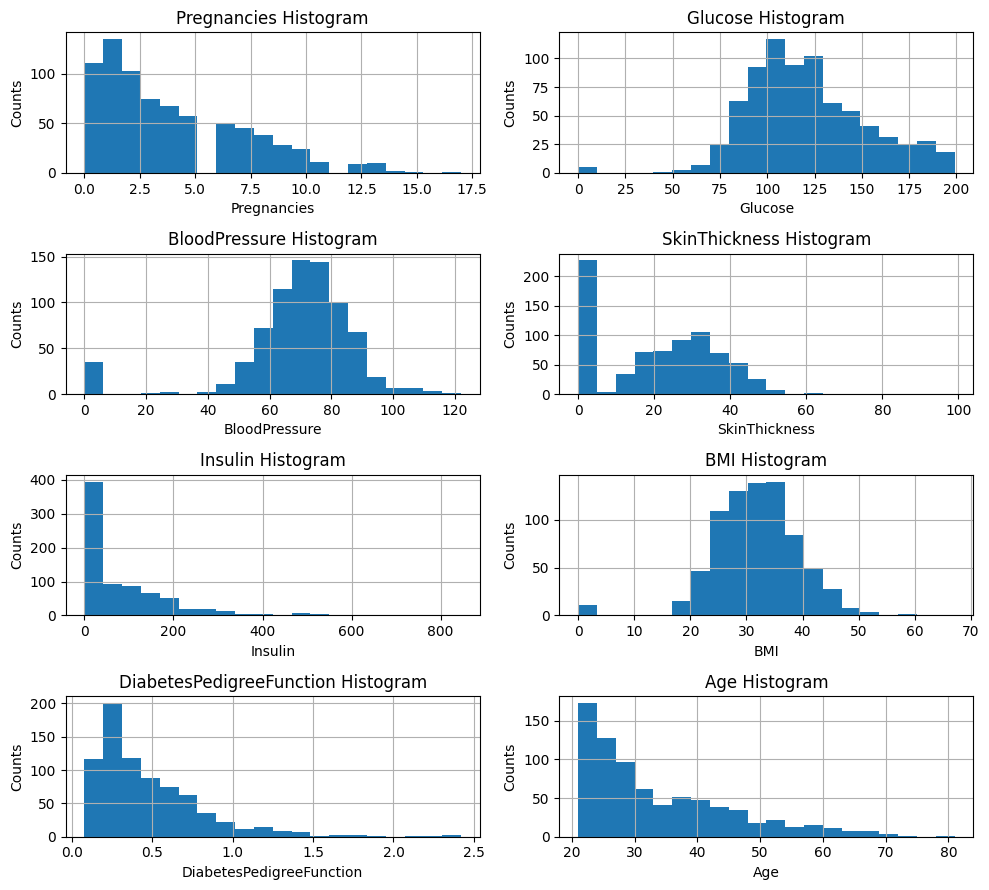

In [76]:
columns = ['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']
figure, axes = plt.subplots(4, 2, figsize=(10,9))

axes = axes.flatten()
for idx, col in enumerate(columns):
    df[col].hist(bins=20, ax=axes[idx])
    axes[idx].set_title(f'{col} Histogram')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Counts')

plt.tight_layout()
plt.show()

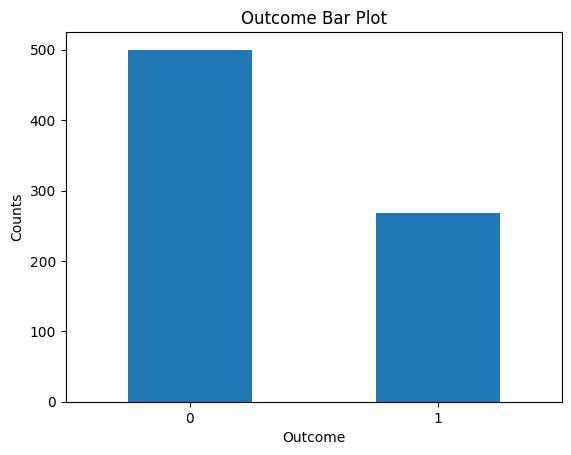

In [77]:
df['Outcome'].value_counts().plot.bar()
plt.xticks(rotation=0)
plt.title('Outcome Bar Plot')
plt.xlabel('Outcome')
plt.ylabel('Counts')
plt.show()

## Task 2

### Convert DataFrame to Numpy arrays

In [78]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((768, 8), (768,))

### Train and Test split

In [79]:
seed = 0

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((537, 8), (537,), (231, 8), (231,))

## Task 3

### Create a Logistic Regression Model

In [80]:
model = LogisticRegression(max_iter=5000, random_state=seed)

### Train model on training set

In [81]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

### Evaluate Model on test set

In [82]:
y_pred = model.predict(x_test)
y_pred

array([1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0])

In [83]:
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model for the test set is: {accuracy_percentage}')

The accuracy of the model for the test set is: 77.92


### Evaluate on train set

In [84]:
y_train_pred = model.predict(x_train)
y_train_pred

array([1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,

In [85]:
accuracy = accuracy_score(y_train, y_train_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model for the train set is: {accuracy_percentage}')

The accuracy of the model for the train set is: 76.54


*The accuracy of the test set is slightly higher than the train's set, by only 1,38%. This demonstrates that the model has similar performance on the data, without a clear indication of overfitting.*

## Task 4

### Glucose and Outcome Correlation

In [86]:
group = df.groupby('Outcome')
means = group['Glucose'].mean()
means

,Glucose
Outcome,
0,109.980000
1,141.257463


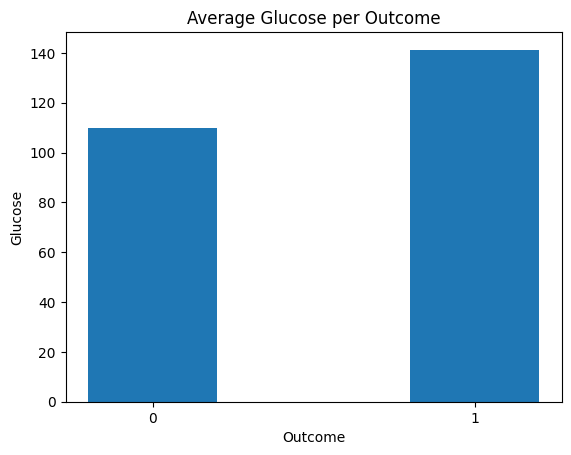

In [87]:
plt.bar(means.index, means.values, width=0.4)
plt.xlabel('Outcome')
plt.ylabel('Glucose')
plt.title('Average Glucose per Outcome')
plt.xticks([0, 1])

plt.show()

*After calculating the mean glucose levels of patients that have diabetes and patients that do not, it can be seen that the diabetic group has approximately 31.28 more glucose units, on average. This provides evidence regarding the clinical statement that associates diabetes with higher glucose levels. However, it also shows that not every patient with high glucose levels has diabetes.*

## Task 5

### Accuracy Based on Age Group

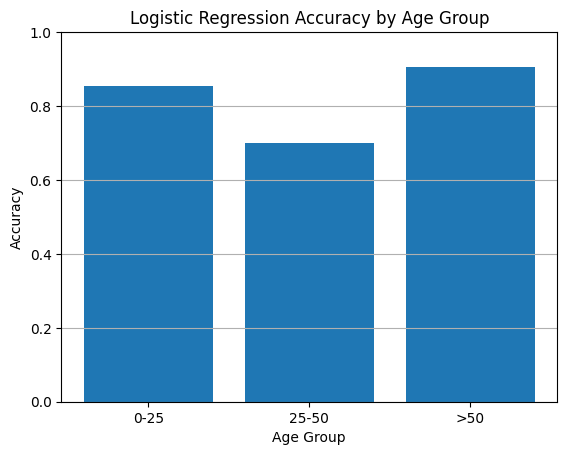

In [88]:
mask_1 = x_test[:, 7] <= 25
mask_2 = (x_test[:, 7] > 25) & (x_test[:, 7] <= 50)
mask_3 = x_test[:, 7] > 50

y_under25 = y_test[mask_1]
pred_under25 = y_pred[mask_1]

y_25to50 = y_test[mask_2]
pred_25to50 = y_pred[mask_2]

y_over50 = y_test[mask_3]
pred_over50 = y_pred[mask_3]

accuracy_under25 = accuracy_score(y_under25, pred_under25)
accuracy_under50 = accuracy_score(y_25to50, pred_25to50)
accuracy_over50 = accuracy_score(y_over50, pred_over50)

ages = ['0-25', '25-50', '>50']
accuracies = [accuracy_under25, accuracy_under50, accuracy_over50]

plt.bar(ages, accuracies)
plt.xlabel('Age Group')
plt.ylabel('Accuracy')
plt.title('Logistic Regression Accuracy by Age Group')
plt.grid(axis='y')
plt.ylim(0, 1)
plt.show()

*The classifier seems to perform better for the age groups 0-25 and >50, demonstrating that for older and younger ages the diagnosis is clearer. However, a bigger sample size would determine better how meaningful these differences are.*

## Task 6

*It is worse for the classifier to mistakely predict that a patient does not have diabetes, but in reality they do. That is because the diagnosis and the proper treatment will be delayed, which can be dentrimental for the patient. So in healthcare, False Negatives are dangerous.*

# Part 2: Linear Regression

## Task 1

### Load, Convert to Numpy and Split the Dataset

In [93]:
df = pd.read_csv('diabetes.csv')

input_df = df[['Pregnancies', 'BloodPressure', 'BMI', 'Age']]
targets_df = df['Glucose']

x = input_df.to_numpy()
y= targets_df.to_numpy()

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=seed)


## Task 2

### Linear Regression model and MSE-MAE Comparison

In [94]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("Mean Squared Error:", round(mse, 2))
print("Mean Absolute Error:", round(mae, 2))

Mean Squared Error: 929.89
Mean Absolute Error: 23.6


*The more appropriate metric would be MAE since it calculates the mean absolute error in the same units as glucose. Also, it is less sensitive on outliers, meaning it reflects realistic numbers without being affected by large errors.*

## Task 3

### Data Normalization

In [95]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train = scaler.transform(x_train)
x_test = scaler.transform(x_test)

### Model Training-Evaluation

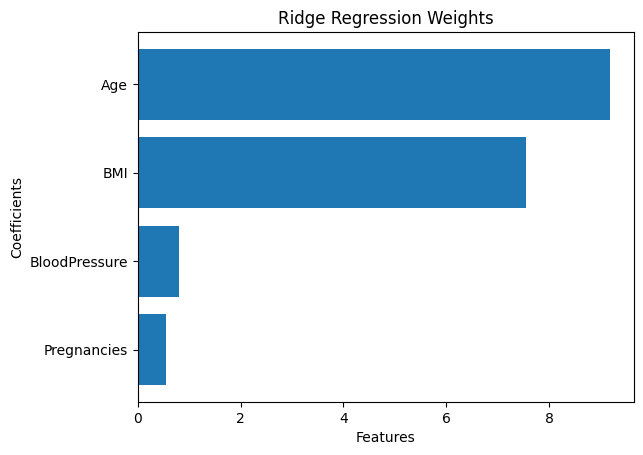

In [96]:
model = Ridge(alpha=1)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

coeffs = model.coef_
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Ridge Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

*As it can be seen in the bar plot, the 2 most important features are Age and BMI, since the larger bars demonstrate higher importance. Blood Pressure and Pregnancies play a singificantly less important role when it comes to glucose levels.*